In [1]:
# ... [Your imports stay the same] ...
!pip install -q albumentations omrdatasettools

import os, sys, time, json, random, zipfile, urllib.request
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from pathlib import Path
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
# 1. SETUP DIRECTORIES
DEVICE   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK_DIR = Path('/kaggle/working')
DATA_DIR = WORK_DIR / 'muscima'
DATA_DIR.mkdir(parents=True, exist_ok=True)

# 2. MODERN DOWNLOAD METHOD (Using omrdatasettools)
from omrdatasettools import Downloader, OmrDataset

def download_muscima_modern(target_dir: Path):
    downloader = Downloader()
    print("Downloading CVC-MUSCIMA via OMR Dataset Tools...")
    # This specifically targets the staff removal subset
    downloader.download_and_extract_dataset(
        OmrDataset.CvcMuscima_StaffRemoval, 
        str(target_dir)
    )
    # The library creates this specific folder name
    return target_dir / "cvcmuscima_staffremoval"

# Execute
MUSCIMA_ROOT = download_muscima_modern(DATA_DIR)

# 3. SET SR_ROOT (The directory where the actual images live)
# We check a few common locations because zip structures can be nested
possible_paths = [
    MUSCIMA_ROOT / 'staffline-removal',
    MUSCIMA_ROOT / 'cvcmuscima_staffremoval' / 'staffline-removal',
    Path('/kaggle/working/muscima/CvcMuscima-Distortions')
]

SR_ROOT = None
for p in possible_paths:
    if p.exists():
        SR_ROOT = p
        break

if SR_ROOT:
    print(f"✅ Success! SR_ROOT set to: {SR_ROOT}")
    # Verify content
    subdirs = [d.name for d in SR_ROOT.iterdir() if d.is_dir()]
    print(f"Folders found: {subdirs}")
else:
    print("❌ Could not find staffline-removal folder. Check /kaggle/working manually.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 kB 1.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.7/105.7 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.1/117.1 kB 7.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Downloading: https://github.com/apacha/OMR-Datasets/releases/download/datasets/CVCMUSCIMA_SR.zip Bytes: 2023350169 into CVCMUSCIMA_SR.zip



Extracting CVCMUSCIMA_SR.zip dataset...
✅ Success! SR_ROOT set to: /kaggle/working/muscima/CvcMuscima-Distortions
Folders found: ['staffline-thickness-variation-v1', 'thickness-ratio', 'staffline-y-variation-v2', 'kanungo', 'staffline-thickness-variation-v2', 'rotated', 'staffline-y-variation-v1', 'ideal', 'whitespeckles', 'interrupted', 'curvature', 'typeset-emulation']


In [2]:
print(SR_ROOT)

/kaggle/working/muscima/CvcMuscima-Distortions


In [3]:
base_path = Path('/kaggle/working/muscima')

distortion = "ideal"

distort_root = base_path / 'CvcMuscima-Distortions' / distortion
    
if not distort_root.exists():
    print(f"❌ Error: Path {distort_root} does not exist.")
    pass
    
    # 2. Find all writer folders (e.g., w-01, w-02...)

for d in distort_root.iterdir():
    if d.is_dir():
        print(d)
        
writer_folders = sorted([d for d in distort_root.iterdir() if d.is_dir()])
print(f"🔍 Distortion: {distortion}")
print(f"📊 Found {len(writer_folders)} writer folders.\n")

total_images = 0
    
    # 3. Explore the first few writers to verify internal structure
for writer in writer_folders[:3]:  # Checking first 3 writers as samples
    img_dir = writer / 'image'
    gt_dir = writer / 'gt'
    sym_dir = writer / 'symbol'
    
    # Get counts
    num_imgs = len(list(img_dir.glob('*.png'))) if img_dir.exists() else 0
    num_gts = len(list(gt_dir.glob('*.png'))) if gt_dir.exists() else 0
    num_syms = len(list(sym_dir.glob('*.png'))) if sym_dir.exists() else 0
        
    total_images += num_imgs

    print(f"📂 Writer: {writer.name}")
    print(f"   - Input Images ('image/'): {num_imgs} files")
    print(f"   - Ground Truth ('gt/'):    {num_gts} files")
    print(f"   - Symbols      ('symbol/'):{num_syms} files")
    
        # Verify if filenames match between input and ground truth
    if num_imgs > 0 and num_gts > 0:
        first_img = sorted(list(img_dir.glob('*.png')))[0].name
        first_gt = sorted(list(gt_dir.glob('*.png')))[0].name
        status = "✅ MATCH" if first_img == first_gt else "❌ MISMATCH"
        print(f"   - Pairing Check: {first_img} <-> {first_gt} ({status})")
    print("-" * 40)

    # 4. Final summary calculation for the entire distortion set
    # (50 writers * 20 pages = 1000 images total per distortion)
total_in_set = sum(len(list((w / 'image').glob('*.png'))) for w in writer_folders)
print(f"\n✅ Total images found in '{distortion}': {total_in_set}")

/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-35
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-30
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-39
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-49
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-32
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-12
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-46
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-21
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-24
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-19
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-29
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-08
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-15
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-03
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-11
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-45
/kaggle/working/muscima/CvcMuscima-Distortions/ideal/w-50
/kaggle/workin

In [4]:
import os
from pathlib import Path

def explore_muscima_nested(base_path: Path, number,distortion='ideal'):
    """
    Specifically designed for the CVC-MUSCIMA Distortions dataset.
    Structure: muscima / CvcMuscima-Distortions / [distortion] / [writer] / [subfolders]
    """
    # 1. Define the distortion path
    distort_root = base_path / 'CvcMuscima-Distortions' / distortion
    
    if not distort_root.exists():
        print(f"❌ Error: Path {distort_root} does not exist.")
        return

    # 2. Find all writer folders (e.g., w-01, w-02...)
    writer_folders = sorted([d for d in distort_root.iterdir() if d.is_dir()])
    print(f"🔍 Distortion: {distortion}")
    print(f"📊 Found {len(writer_folders)} writer folders.\n")

    total_images = 0
    
    # 3. Explore the first few writers to verify internal structure
    for writer in writer_folders[:3]:  # Checking first 3 writers as samples
        img_dir = writer / 'image'
        gt_dir = writer / 'gt'
        sym_dir = writer / 'symbol'
        
        # Get counts
        num_imgs = len(list(img_dir.glob('*.png'))) if img_dir.exists() else 0
        num_gts = len(list(gt_dir.glob('*.png'))) if gt_dir.exists() else 0
        num_syms = len(list(sym_dir.glob('*.png'))) if sym_dir.exists() else 0
        
        total_images += num_imgs
        
        print(f"📂 Writer: {writer.name}")
        print(f"   - Input Images ('image/'): {num_imgs} files")
        print(f"   - Ground Truth ('gt/'):    {num_gts} files")
        print(f"   - Symbols      ('symbol/'):{num_syms} files")
        
        # Verify if filenames match between input and ground truth
        if num_imgs > 0 and num_gts > 0:
            first_img = sorted(list(img_dir.glob('*.png')))[0].name
            first_gt = sorted(list(gt_dir.glob('*.png')))[0].name
            status = "✅ MATCH" if first_img == first_gt else "❌ MISMATCH"
            print(f"   - Pairing Check: {first_img} <-> {first_gt} ({status})")
        print("-" * 40)

    # 4. Final summary calculation for the entire distortion set
    # (50 writers * 20 pages = 1000 images total per distortion)
    total_in_set = sum(len(list((w / 'image').glob('*.png'))) for w in writer_folders)
    print(f"\n✅ Total images found in '{distortion}': {total_in_set}")
    return int(total_in_set)

# --- Execution ---
# Point this to the 'muscima' folder in your /kaggle/working directory
BASE_PATH = Path('/kaggle/working/muscima')
total_images = explore_muscima_nested(BASE_PATH, total_images, distortion='ideal')

🔍 Distortion: ideal
📊 Found 50 writer folders.

📂 Writer: w-01
   - Input Images ('image/'): 20 files
   - Ground Truth ('gt/'):    20 files
   - Symbols      ('symbol/'):20 files
   - Pairing Check: p001.png <-> p001.png (✅ MATCH)
----------------------------------------
📂 Writer: w-02
   - Input Images ('image/'): 20 files
   - Ground Truth ('gt/'):    20 files
   - Symbols      ('symbol/'):20 files
   - Pairing Check: p001.png <-> p001.png (✅ MATCH)
----------------------------------------
📂 Writer: w-03
   - Input Images ('image/'): 20 files
   - Ground Truth ('gt/'):    20 files
   - Symbols      ('symbol/'):20 files
   - Pairing Check: p001.png <-> p001.png (✅ MATCH)
----------------------------------------

✅ Total images found in 'ideal': 1000


In [5]:
total_images
ideal_root = SR_ROOT / 'ideal'

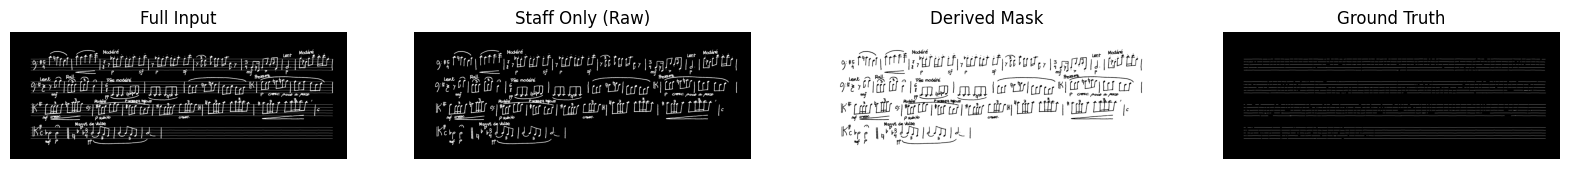

In [6]:
def load_triplet(writer_dir: Path, page: str):
    """
    Load the three image types for one (writer, page) pair.
    Based on your sidebar: image, gt, and symbol.
    """
    # Use the folder names seen in your sidebar screenshot
    full_path  = writer_dir / 'image' / page
    gt_path    = writer_dir / 'gt'    / page
    # Note: 'symbol' is what appears in your directory, check if it contains staff lines
    staff_path = writer_dir / 'symbol' / page 

    full_img  = cv2.imread(str(full_path), cv2.IMREAD_GRAYSCALE)
    gt_img    = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)
    staff_img = cv2.imread(str(staff_path), cv2.IMREAD_GRAYSCALE)

    # Error checking: ensure images actually loaded
    if full_img is None or gt_img is None or staff_img is None:
        raise FileNotFoundError(f"Could not load images for {page} in {writer_dir}. "
                                f"Check if 'symbol' folder is actually 'staff_only'.")
        
    return full_img, gt_img, staff_img

def derive_staff_mask(staff_only_img: np.ndarray) -> np.ndarray:
    """
    Convert the staff_only image into a binary mask.
    """
    mask = (staff_only_img < 128).astype(np.uint8) * 255
    return mask

# 1. Correct the root path to match your actual directory structure
# Based on your image: /kaggle/working/muscima/CvcMuscima-Distortions/ideal
ideal_root = Path('/kaggle/working/muscima/CvcMuscima-Distortions/ideal')

# 2. Get the first writer (w-01) and first page
try:
    sample_writer = sorted([d for d in ideal_root.iterdir() if d.is_dir()])[0]
    sample_page   = sorted((sample_writer / 'image').glob('*.png'))[0].name

    # 3. Load and process
    full_img, gt_img, staff_img = load_triplet(sample_writer, sample_page)
    mask = derive_staff_mask(staff_img)

    # 4. Visualization (remains the same)
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))
    images_to_show = [full_img, staff_img, mask, gt_img]
    titles = ['Full Input', 'Staff Only (Raw)', 'Derived Mask', 'Ground Truth']
    
    for ax, img, title in zip(axes, images_to_show, titles):
        ax.imshow(img, cmap='gray')
        ax.set_title(title)
        ax.axis('off')
    plt.show()

except IndexError:
    print("❌ Error: No directories or images found. Check if ideal_root path is correct.")
except FileNotFoundError as e:
    print(f"❌ {e}")

In [7]:
def build_dataset_index(
    sr_root: Path,
    distortions: list = ['ideal'],
    val_writers: list = None,
) -> tuple[list, list]:
    """
    Scans CVC-MUSCIMA and returns lists of (image_path, mask_path) tuples.
    """
    if val_writers is None:
        val_writers = list(range(41, 51))

    train_pairs, val_pairs = [], []

    for distortion in distortions:
        # FIX: Ensure the 'CvcMuscima-Distortions' path segment is included
        distort_root = sr_root / 'CvcMuscima-Distortions' / distortion
        
        if not distort_root.exists():
            print(f"Warning: distortion '{distortion}' not found at {distort_root}, skipping")
            continue

        for writer_dir in sorted(distort_root.iterdir()):
            # Safety check: skip hidden files or non-writer folders
            if not writer_dir.is_dir() or not writer_dir.name.startswith('w-'):
                continue

            try:
                # Parse writer number (e.g., "w-01" -> 1)
                writer_num = int(writer_dir.name.split('-')[1])
            except (IndexError, ValueError):
                continue

            image_dir = writer_dir / 'image'
            # FIX: Mapping to the correct folder found in your screenshots
            # If you want to predict staff lines, use 'symbol' or your specific staff folder
            staff_dir = writer_dir / 'symbol' 

            if not image_dir.exists() or not staff_dir.exists():
                continue

            for img_path in sorted(image_dir.glob('*.png')):
                staff_path = staff_dir / img_path.name
                if not staff_path.exists():
                    continue

                pair = (str(img_path), str(staff_path))

                if writer_num in val_writers:
                    val_pairs.append(pair)
                else:
                    train_pairs.append(pair)

    return train_pairs, val_pairs

# --- Execution ---
# Ensure BASE_PATH points to the directory containing 'CvcMuscima-Distortions'
BASE_PATH = Path('/kaggle/working/muscima')
train_pairs, val_pairs = build_dataset_index(
    BASE_PATH,
    distortions=['ideal'],
    val_writers=list(range(41, 51))
)

print(f"Train pairs: {len(train_pairs)}")
print(f"Val pairs:   {len(val_pairs)}")

Train pairs: 800
Val pairs:   200


In [8]:
def derive_staff_mask(staff_only_img: np.ndarray) -> np.ndarray:
    """
    Convert the staff_only image into a binary mask.
    In CVC-MUSCIMA, staff_only images use 255 for background and 0 for lines.
    Our target: 255 = staff line pixel, 0 = background.
    """
    if staff_only_img is None:
        return None
    # Thresholding and inverting: black pixels (<128) become 255 (white)
    mask = (staff_only_img < 128).astype(np.uint8) * 255
    return mask

class MUSCIMADataset(Dataset):
    """
    PyTorch Dataset for CVC-MUSCIMA staff line removal.
    Uses random cropping at native resolution to preserve fine line details.
    """

    def __init__(
        self,
        pairs: list,               # list of (image_path, staff_only_path) tuples
        crop_size: int = 256,      # random crop size during training
        augment: bool = True,
        scale_range: tuple = (0.5, 1.0),  # multi-scale "zoom" crops
    ):
        self.pairs = pairs
        self.crop_size = crop_size
        self.augment = augment
        self.scale_range = scale_range

       # Spatial transforms (Identical for image and mask)
        self.spatial_tfm = A.Compose([
            A.HorizontalFlip(p=0.5),
            # 'fill' is the modern parameter for Rotate
            A.Rotate(limit=5, p=0.5, border_mode=cv2.BORDER_CONSTANT, fill=255),
            # 'fill' is the modern parameter for ElasticTransform
            A.ElasticTransform(alpha=30, sigma=5, p=0.3, border_mode=cv2.BORDER_CONSTANT, fill=255),
        ]) if augment else None

        # Pixel-level transforms (Applied to input image only)
        self.pixel_tfm = A.Compose([
            A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.6),
            A.GaussianBlur(blur_limit=(3, 5), p=0.3),
            # 'std_range' is used for Gaussian noise ranges in recent versions
            A.GaussNoise(std_range=(0.01, 0.05), p=0.4), 
            A.Sharpen(alpha=(0.1, 0.3), p=0.2),
        ]) if augment else None

        self.normalize = A.Compose([
            A.Normalize(mean=0.0, std=1.0, max_pixel_value=255.0),
            ToTensorV2(),
        ])

    def __len__(self):
        return len(self.pairs)

    def _random_crop(self, image: np.ndarray, mask: np.ndarray):
        """Extracts corresponding crops from image and mask."""
        H, W = image.shape

        if self.augment:
            scale = random.uniform(*self.scale_range)
            actual_crop = int(self.crop_size / scale)
            actual_crop = min(actual_crop, H, W)
            y = random.randint(0, max(0, H - actual_crop))
            x = random.randint(0, max(0, W - actual_crop))
        else:
            actual_crop = self.crop_size
            y = max(0, (H - actual_crop) // 2)
            x = max(0, (W - actual_crop) // 2)

        img_crop = image[y:y+actual_crop, x:x+actual_crop]
        mask_crop = mask[y:y+actual_crop, x:x+actual_crop]

        # Resize back to target crop_size for batching
        if img_crop.shape[0] != self.crop_size or img_crop.shape[1] != self.crop_size:
            img_crop = cv2.resize(img_crop, (self.crop_size, self.crop_size), interpolation=cv2.INTER_LINEAR)
            mask_crop = cv2.resize(mask_crop, (self.crop_size, self.crop_size), interpolation=cv2.INTER_NEAREST)

        return img_crop, mask_crop

    def __getitem__(self, idx: int) -> dict:
        img_path, staff_path = self.pairs[idx]
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        staff_only = cv2.imread(staff_path, cv2.IMREAD_GRAYSCALE)

        # Fallback for failed loads
        if image is None or staff_only is None:
            image = np.full((self.crop_size, self.crop_size), 255, dtype=np.uint8)
            staff_only = np.full((self.crop_size, self.crop_size), 255, dtype=np.uint8)

        mask = derive_staff_mask(staff_only)
        image, mask = self._random_crop(image, mask)

        if self.augment:
            # Spatial: Affects both
            transformed = self.spatial_tfm(image=image, mask=mask)
            image, mask = transformed['image'], transformed['mask']
            # Pixel: Affects image only
            image = self.pixel_tfm(image=image)['image']

        # Binarize mask to clean interpolation artifacts
        mask = (mask > 127).astype(np.uint8) * 255
        
        result = self.normalize(image=image, mask=mask)
        
        # Ensure mask is a binary float tensor (1, H, W)
        mask_t = (result['mask'] > 0.5).float()
        if mask_t.dim() == 2:
            mask_t = mask_t.unsqueeze(0)

        return {
            'image': result['image'], 
            'mask': mask_t,
            'img_path': img_path,
        }

# Verify with training pairs from previous build_dataset_index cell
print("Initializing MUSCIMA Datasets...")
train_ds = MUSCIMADataset(train_pairs, crop_size=256, augment=True)
val_ds = MUSCIMADataset(val_pairs, crop_size=256, augment=False)

print(f"Dataset summary: {len(train_ds)} train samples, {len(val_ds)} validation samples.")

Initializing MUSCIMA Datasets...
Dataset summary: 800 train samples, 200 validation samples.


Train: 800 crops | Val: 200 crops
Train batches: 50 | Val batches: 13


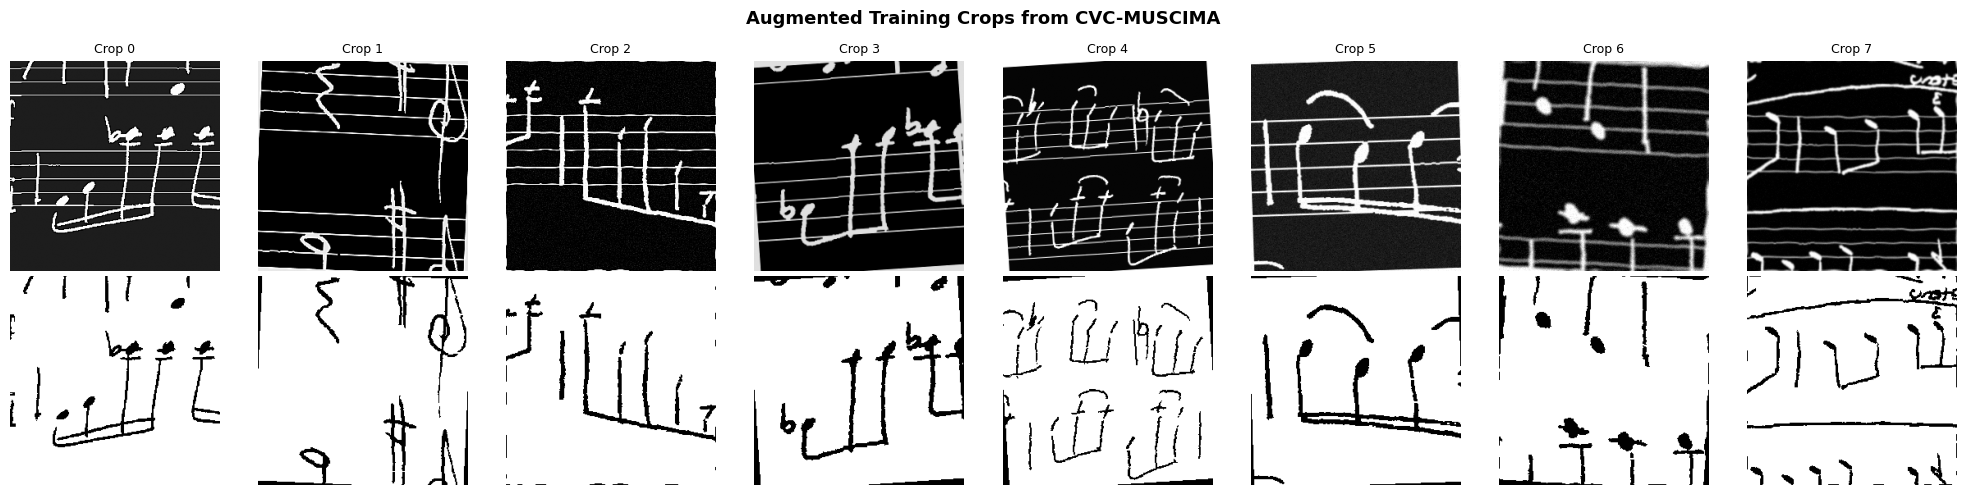

Average staff line coverage in batch: 92.7%


In [9]:
def get_muscima_loaders(train_pairs, val_pairs, crop_size=256, batch_size=16):
    train_ds = MUSCIMADataset(train_pairs, crop_size=crop_size, augment=True)
    val_ds   = MUSCIMADataset(val_pairs,   crop_size=crop_size, augment=False)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=2, pin_memory=True, drop_last=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                              num_workers=2, pin_memory=True)

    print(f"Train: {len(train_ds)} crops | Val: {len(val_ds)} crops")
    print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")
    return train_loader, val_loader

train_loader, val_loader = get_muscima_loaders(train_pairs, val_pairs,
                                                crop_size=256, batch_size=16)

# Visualize augmented crops from the real dataset
batch = next(iter(train_loader))
images, masks = batch['image'], batch['mask']

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for i in range(8):
    img  = images[i, 0].numpy()
    mask = masks[i, 0].numpy()
    axes[0, i].imshow(img,  cmap='gray', vmin=0, vmax=1)
    axes[1, i].imshow(mask, cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f'Crop {i}', fontsize=9)
    for ax in axes[:, i]: ax.axis('off')

axes[0, 0].set_ylabel('Input crops\n(with lines)', fontsize=10)
axes[1, 0].set_ylabel('Staff masks\n(targets)',    fontsize=10)
plt.suptitle('Augmented Training Crops from CVC-MUSCIMA', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Sanity check: mask coverage should be ~5-15%
coverage = masks.float().mean().item() * 100
print(f"Average staff line coverage in batch: {coverage:.1f}%")

In [26]:
# ── Paste the full UNet from Cell 5 of the previous notebook ──────
# (ConvBlock, EncoderBlock, DecoderBlock, UNet classes)
# Repeated here for completeness:

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch,  out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        ]
        if dropout > 0: layers.append(nn.Dropout2d(dropout))
        self.block = nn.Sequential(*layers)
    def forward(self, x): return self.block(x)

class EncoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        self.conv = ConvBlock(in_ch, out_ch, dropout)
        self.pool = nn.MaxPool2d(2, 2)
    def forward(self, x):
        skip = self.conv(x)
        return skip, self.pool(skip)

class DecoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        self.up   = nn.Sequential(nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
                                   nn.Conv2d(in_ch, in_ch//2, 1))
        self.conv = ConvBlock(in_ch, out_ch, dropout)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape != skip.shape:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=True)
        return self.conv(torch.cat([skip, x], dim=1))

class UNet(nn.Module):
    def __init__(self, in_channels=1, base_channels=64, depth=4, dropout=0.1):
        super().__init__()
        self.encoders = nn.ModuleList()
        self.decoders = nn.ModuleList()
        ch_in, ch_out = in_channels, base_channels
        for i in range(depth):
            self.encoders.append(EncoderBlock(ch_in, ch_out, dropout if i >= depth//2 else 0.0))
            ch_in, ch_out = ch_out, ch_out * 2
        self.bottleneck  = ConvBlock(ch_in, ch_out, dropout)
        ch_in = ch_out
        for i in range(depth):
            ch_out = ch_in // 2
            self.decoders.append(DecoderBlock(ch_in, ch_out, dropout if i < depth//2 else 0.0))
            ch_in = ch_out
        self.output_conv = nn.Conv2d(ch_in, 1, 1)
    def forward(self, x):
        skips = []
        for enc in self.encoders:
            skip, x = enc(x); skips.append(skip)
        x = self.bottleneck(x)
        for i, dec in enumerate(self.decoders):
            x = dec(x, skips[-(i+1)])
        return self.output_conv(x)

model = UNet(in_channels=1, base_channels=64, depth=4, dropout=0.15).to(DEVICE)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {params:,}")
dummy = torch.randn(2, 1, 256, 256).to(DEVICE)
out = model(dummy)
print(f"Forward pass: {dummy.shape} → {out.shape}  ✓")

Model parameters: 28,947,521
Forward pass: torch.Size([2, 1, 256, 256]) → torch.Size([2, 1, 256, 256])  ✓


In [30]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth
    def forward(self, pred, target):
        pred = torch.sigmoid(pred)
        p, t = pred.view(-1), target.view(-1)
        inter = (p * t).sum()
        return 1 - (2*inter + self.smooth) / (p.sum() + t.sum() + self.smooth)

class FocalLoss(nn.Module):
    """
    Focal loss is better than BCE for CVC-MUSCIMA because real handwritten lines
    are sometimes very faint or partially merged with symbols — these 'hard'
    pixels benefit from focal loss's emphasis on difficult examples.
    """
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha  # weight for positive class (staff lines)
        self.gamma = gamma  # focusing strength (2.0 is standard)
    def forward(self, pred, target):
        bce = F.binary_cross_entropy_with_logits(pred, target, reduction='none')
        p_t = torch.exp(-bce) # Stable way to get probability for weighting
        alpha_t = self.alpha * target + (1 - self.alpha) * (1 - target)
        return (alpha_t * (1 - p_t)**self.gamma * bce).mean()

class CombinedLoss(nn.Module):
    def __init__(self, focal_weight=0.3, dice_weight=0.7):
        super().__init__()
        self.fw = focal_weight
        self.dw = dice_weight
        self.focal = FocalLoss(alpha=0.75, gamma=2.0)
        self.dice  = DiceLoss()
    def forward(self, pred, target):
        return self.fw * self.focal(pred, target) + self.dw * self.dice(pred, target)

def compute_metrics(pred, target, threshold=0.5, eps=1e-6):
    pred = torch.sigmoid(pred) # ✅ Convert logits to probabilities
    pred_b = (pred > threshold).float()
    p, t   = pred_b.view(-1), target.view(-1)
    inter  = (p * t).sum()
    union  = (p + t - p*t).sum()
    dice   = (2*inter + eps) / (p.sum() + t.sum() + eps)
    iou    = (inter + eps) / (union + eps)
    prec   = (inter + eps) / (p.sum() + eps)   # precision: of predicted lines, how many are real
    rec    = (inter + eps) / (t.sum() + eps)   # recall: of real lines, how many did we find
    return {'iou': iou.item(), 'dice': dice.item(), 'precision': prec.item(), 'recall': rec.item()}

# ── CONFIG tuned for CVC-MUSCIMA ──────────────────────────────────
CONFIG = dict(
    epochs          = 20,
    lr              = 5e-5,      # lower than synthetic — real data needs more careful optimization
    weight_decay    = 1e-4,
    lr_patience     = 8,
    lr_factor       = 0.5,
    min_lr          = 1e-8,
    early_stop      = 20,
    threshold       = 0.5,
    use_amp         = True,
    grad_clip       = 1.0,
)

criterion = CombinedLoss(focal_weight=0.3, dice_weight=0.7)
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=CONFIG['lr_patience'],
    factor=CONFIG['lr_factor'], min_lr=CONFIG['min_lr'])
scaler = torch.amp.GradScaler('cuda', enabled=CONFIG['use_amp'])
print("Ready to train!")

Ready to train!


In [31]:
from pathlib import Path

# Define where to save your models
CKPT_DIR = Path('/kaggle/working/checkpoints')

# Create the directory if it doesn't exist
CKPT_DIR.mkdir(parents=True, exist_ok=True)

print(f"✅ Checkpoint directory ready: {CKPT_DIR}")

def run_epoch(model, loader, optimizer, criterion, scaler, train=True):
    model.train() if train else model.eval()
    totals = {'loss': 0, 'iou': 0, 'dice': 0, 'precision': 0, 'recall': 0, 'n': 0}

    # Context manager handles gradient tracking automatically
    ctx = torch.enable_grad() if train else torch.no_grad()
    
    with ctx:
        for batch in tqdm(loader, desc='Train' if train else 'Val ', leave=False):
            images = batch['image'].to(DEVICE, non_blocking=True)
            masks  = batch['mask'].to(DEVICE, non_blocking=True)
            B = images.size(0)

            if train:
                optimizer.zero_grad()

            # FIX: Updated to the new unified amp API
            with torch.amp.autocast('cuda', enabled=CONFIG['use_amp']):
                preds = model(images)
                loss  = criterion(preds, masks)

            if train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                # Gradient clipping prevents "exploding gradients" in deep U-Nets
                nn.utils.clip_grad_norm_(model.parameters(), CONFIG['grad_clip'])
                scaler.step(optimizer)
                scaler.update()

            # Metric calculation
            with torch.no_grad():
                # We use .detach() to ensure we don't accidentally keep the computation graph in memory
                m = compute_metrics(preds.detach(), masks, CONFIG['threshold'])

            totals['loss']      += loss.item() * B
            totals['iou']       += m['iou'] * B
            totals['dice']      += m['dice'] * B
            totals['precision'] += m['precision'] * B
            totals['recall']    += m['recall'] * B
            totals['n']         += B

    n = totals['n']
    return {k: v/n for k, v in totals.items() if k != 'n'}

history       = []
best_val_loss = float('inf')
best_val_iou  = 0.0
no_improve    = 0

print(f"Training on CVC-MUSCIMA | {DEVICE} | {CONFIG['epochs']} epochs max")
print("=" * 75)

for epoch in range(1, CONFIG['epochs'] + 1):
    t0      = time.time()
    train_m = run_epoch(model, train_loader, optimizer, criterion, scaler, train=True)
    val_m   = run_epoch(model, val_loader,   optimizer, criterion, scaler, train=False)
    scheduler.step(val_m['loss'])
    elapsed = time.time() - t0
    lr_now  = optimizer.param_groups[0]['lr']

    print(f"Ep {epoch:3d}/{CONFIG['epochs']} | lr={lr_now:.1e} | "
          f"TrLoss={train_m['loss']:.4f} | "
          f"VLoss={val_m['loss']:.4f} | IoU={val_m['iou']:.4f} | "
          f"Dice={val_m['dice']:.4f} | Prec={val_m['precision']:.3f} | "
          f"Rec={val_m['recall']:.3f} | {elapsed:.0f}s")

    history.append({'epoch': epoch,
                    'train_loss': train_m['loss'], 'train_iou': train_m['iou'],
                    'val_loss': val_m['loss'],     'val_iou': val_m['iou'],
                    'val_dice': val_m['dice'],     'val_precision': val_m['precision'],
                    'val_recall': val_m['recall'], 'lr': lr_now})

    if val_m['loss'] < best_val_loss:
        best_val_loss, best_val_iou = val_m['loss'], val_m['iou']
        no_improve = 0
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'val_loss': val_m['loss'], 'val_iou': val_m['iou'],
                    'val_dice': val_m['dice'], 'config': CONFIG},
                   CKPT_DIR / 'best_model.pth')
        print(f"  ✓ Best model saved (IoU={best_val_iou:.4f})")
    else:
        no_improve += 1
        if no_improve >= CONFIG['early_stop']:
            print(f"Early stopping — no improvement for {no_improve} epochs")
            break

print(f"\nTraining complete! Best val IoU: {best_val_iou:.4f}")

✅ Checkpoint directory ready: /kaggle/working/checkpoints
Training on CVC-MUSCIMA | cuda | 20 epochs max


Train:   0%|          | 0/50 [00:00<?, ?it/s]

Val :   0%|          | 0/13 [00:00<?, ?it/s]

Ep   1/20 | lr=5.0e-05 | TrLoss=0.0147 | VLoss=0.0133 | IoU=0.9894 | Dice=0.9947 | Prec=0.992 | Rec=0.997 | 29s
  ✓ Best model saved (IoU=0.9894)


Train:   0%|          | 0/50 [00:00<?, ?it/s]

Val :   0%|          | 0/13 [00:00<?, ?it/s]

... (51 outputs left out)

Ep  19/20 | lr=5.0e-05 | TrLoss=0.0088 | VLoss=0.0079 | IoU=0.9903 | Dice=0.9951 | Prec=0.993 | Rec=0.997 | 29s
  ✓ Best model saved (IoU=0.9903)


Train:   0%|          | 0/50 [00:00<?, ?it/s]

Val :   0%|          | 0/13 [00:00<?, ?it/s]

Ep  20/20 | lr=5.0e-05 | TrLoss=0.0087 | VLoss=0.0080 | IoU=0.9887 | Dice=0.9943 | Prec=0.991 | Rec=0.998 | 29s

Training complete! Best val IoU: 0.9903


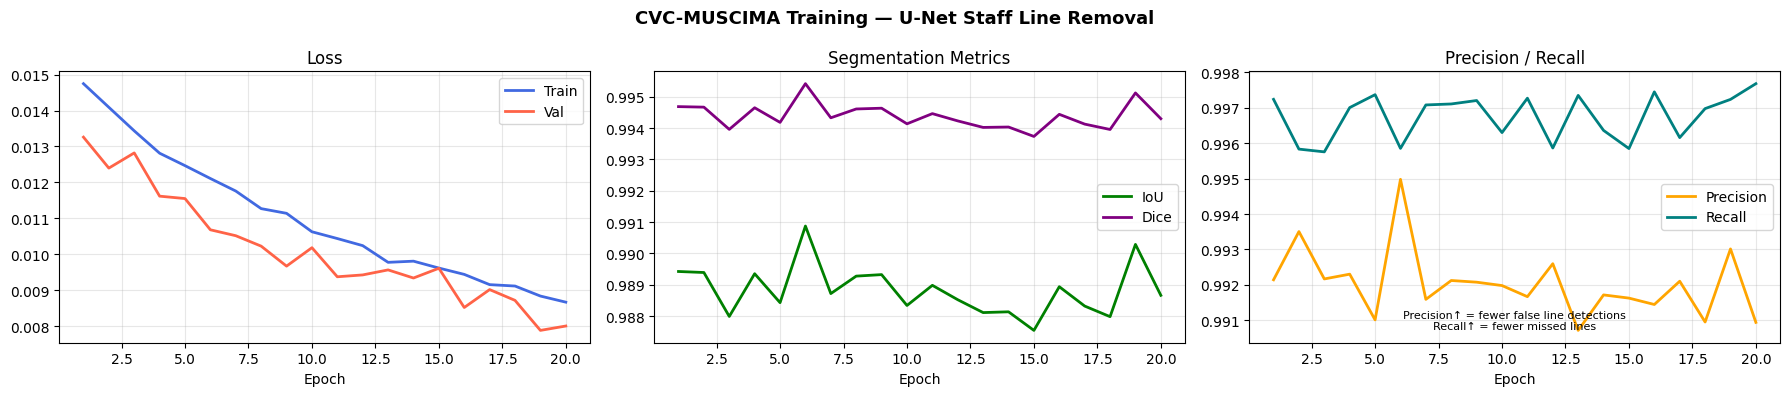

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

epochs_done  = [h['epoch']         for h in history]
train_losses = [h['train_loss']    for h in history]
val_losses   = [h['val_loss']      for h in history]
val_ious     = [h['val_iou']       for h in history]
val_dices    = [h['val_dice']      for h in history]
val_precs    = [h['val_precision'] for h in history]
val_recs     = [h['val_recall']    for h in history]

axes[0].plot(epochs_done, train_losses, label='Train', color='royalblue', lw=2)
axes[0].plot(epochs_done, val_losses,   label='Val',   color='tomato',    lw=2)
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_done, val_ious,  label='IoU',  color='green',  lw=2)
axes[1].plot(epochs_done, val_dices, label='Dice', color='purple', lw=2)
axes[1].set_title('Segmentation Metrics'); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs_done, val_precs, label='Precision', color='orange', lw=2)
axes[2].plot(epochs_done, val_recs,  label='Recall',    color='teal',   lw=2)
axes[2].set_title('Precision / Recall')
axes[2].legend(); axes[2].grid(alpha=0.3)
axes[2].text(0.5, 0.05,
    'Precision↑ = fewer false line detections\nRecall↑ = fewer missed lines',
    transform=axes[2].transAxes, fontsize=8, ha='center')

for ax in axes:
    ax.set_xlabel('Epoch')
plt.suptitle('CVC-MUSCIMA Training — U-Net Staff Line Removal', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(WORK_DIR/'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

Loaded best model: epoch 19, IoU=0.9903


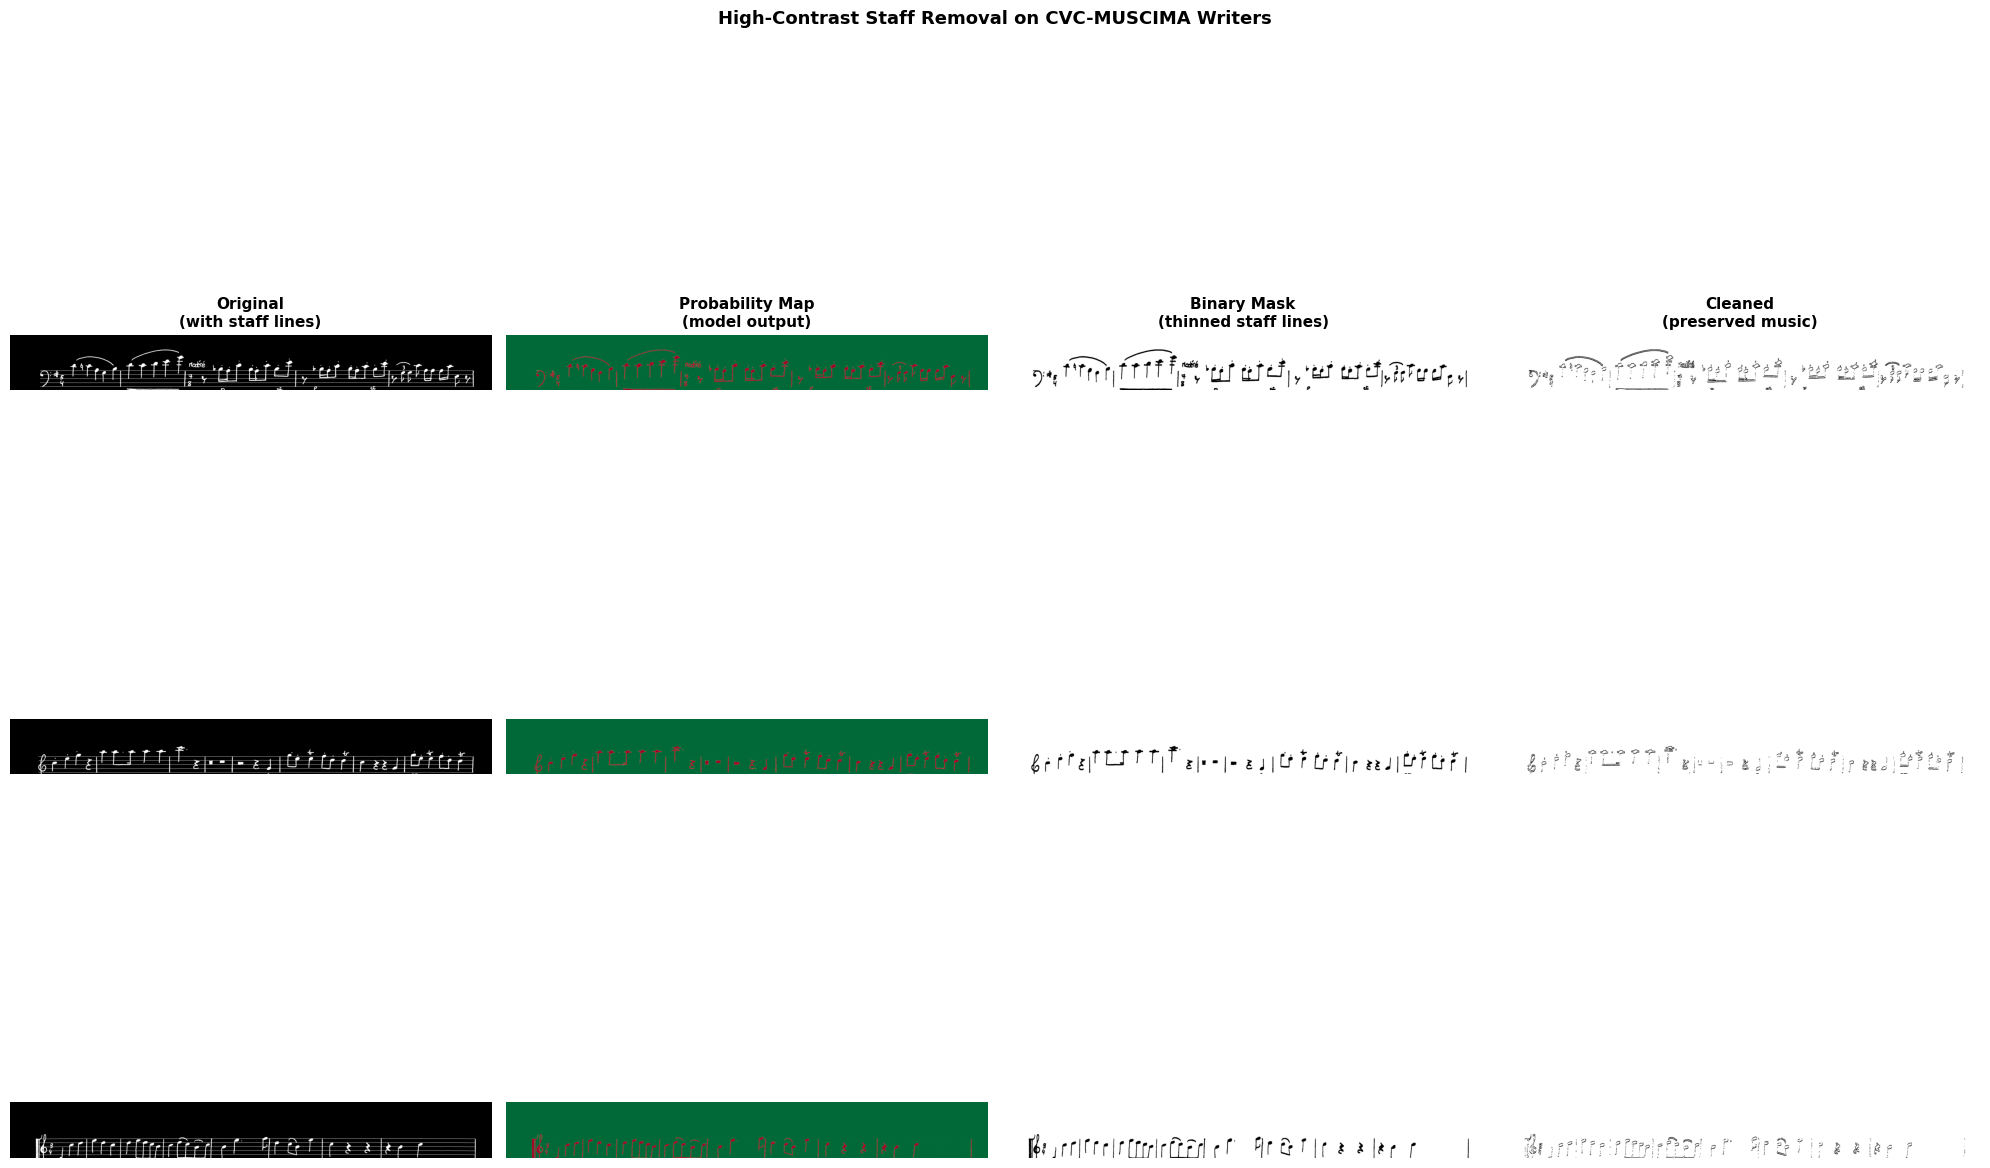

In [46]:
# Load best checkpoint
ckpt = torch.load(CKPT_DIR / 'best_model.pth', map_location=DEVICE)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
print(f"Loaded best model: epoch {ckpt['epoch']}, IoU={ckpt['val_iou']:.4f}")


def predict_full_page(model, image_path: str, threshold=0.5, patch_size=256, overlap=64):
    """
    Full-page prediction for CVC-MUSCIMA with Adaptive Ink Extraction.
    Ensures handwritten notes are dark and crisp while staff lines are removed.
    """
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if image is None: return None, None, None, None
    H, W = image.shape
    step = patch_size - overlap

    # 1. Tiled Inference to handle large CVC-MUSCIMA pages
    pred_sum = np.zeros((H, W), np.float32)
    count_map = np.zeros((H, W), np.float32)

    y_starts = list(range(0, max(1, H - patch_size + 1), step))
    x_starts = list(range(0, max(1, W - patch_size + 1), step))
    if not y_starts or y_starts[-1] + patch_size < H: y_starts.append(max(0, H - patch_size))
    if not x_starts or x_starts[-1] + patch_size < W: x_starts.append(max(0, W - patch_size))

    model.eval()
    with torch.no_grad():
        for y in y_starts:
            for x in x_starts:
                ph, pw = min(patch_size, H - y), min(patch_size, W - x)
                patch = image[y:y+ph, x:x+pw]
                
                # Preprocessing matches training normalization
                resized = cv2.resize(patch, (patch_size, patch_size))
                tensor = torch.from_numpy(resized.astype(np.float32)/255.0).unsqueeze(0).unsqueeze(0).to(DEVICE)
                
                # Model returns logits; apply sigmoid for probabilities
                prob = torch.sigmoid(model(tensor)).squeeze().cpu().numpy()
                prob = cv2.resize(prob, (pw, ph), interpolation=cv2.INTER_LINEAR)
                
                pred_sum[y:y+ph, x:x+pw] += prob
                count_map[y:y+ph, x:x+pw] += 1

    prob_map = pred_sum / np.maximum(count_map, 1e-6)
    
    # 2. Strategic Mask Refinement
    # Binarize the detected staff lines
    mask_bin = ((prob_map > threshold) * 255).astype(np.uint8)
    # Vertical Erosion: Shrinks the mask vertically to avoid overlapping note heads
    v_kern = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 5))
    staff_mask = cv2.erode(mask_bin, v_kern, iterations=1)

    # 3. ADAPTIVE RECONSTRUCTION (Fixes the "lightness")
    # Finds 'ink' relative to local neighborhoods to capture faint strokes
    ink_mask = cv2.adaptiveThreshold(
        image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
        cv2.THRESH_BINARY_INV, 21, 11
    )
    
    # Isolate music: Everything that is ink MINUS the detected staff lines
    music_ink = cv2.subtract(ink_mask, staff_mask)
    
    # Optional: Slightly thicken the symbols if they look too skeletal
    music_ink = cv2.dilate(music_ink, np.ones((2,2), np.uint8), iterations=1)

    
    # 4. DARKENING STEP: Controlled Dilation
    # This slightly thickens the handwritten lines to make them appear darker.
    darken_kernel = np.ones((2, 2), np.uint8)
    music_ink = cv2.dilate(music_ink, darken_kernel, iterations=1)

    # 4. Final High-Contrast Output
    cleaned = np.full_like(image, 255) # White background
    cleaned[music_ink > 0] = 0        # Pure black music

    return image, prob_map, staff_mask, cleaned

 

# --- Visualization ---
val_sample_paths = [p[0] for p in val_pairs[:3]]
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
col_labels = ['Original\n(with staff lines)', 'Probability Map\n(model output)',
              'Binary Mask\n(thinned staff lines)', 'Cleaned\n(preserved music)']

for row, img_path in enumerate(val_sample_paths):
    orig, prob, mask, cleaned = predict_full_page(model, img_path)

    h_show = min(400, orig.shape[0])
    displays = [orig[:h_show], prob[:h_show], mask[:h_show], cleaned[:h_show]]
    cmaps    = ['gray', 'RdYlGn', 'gray', 'gray']

    for col, (img, cmap) in enumerate(zip(displays, cmaps)):
        axes[row, col].imshow(img, cmap=cmap)
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(col_labels[col], fontsize=11, fontweight='bold')
        if col == 0:
            writer = Path(img_path).parts[-3]
            page   = Path(img_path).stem
            axes[row, col].set_ylabel(f'{writer}\n{page}', fontsize=9)

plt.suptitle('High-Contrast Staff Removal on CVC-MUSCIMA Writers', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [34]:
def evaluate_against_gt(model, val_pairs, sr_root, threshold=0.5, num_eval=50):
    """
    Evaluate predicted masks against the actual GT (symbols-only image).
    
    EVALUATION LOGIC:
    The CVC-MUSCIMA 'gt' folder contains the GROUND TRUTH cleaned image
    (symbols with NO staff lines). We can compare our cleaned output to this.
    
    Two metrics:
      1. MASK IoU:   compare predicted staff mask to (full - gt), the 'true' staff mask
      2. Image PSNR: compare our cleaned output to the GT cleaned image
                     Higher PSNR = cleaner removal = closer to ground truth
    """
    mask_ious, psnrs = [], []

    for img_path, staff_path in tqdm(val_pairs[:num_eval], desc='Evaluating'):
        # Derive GT staff mask from staff_only image
        staff_only = cv2.imread(staff_path, cv2.IMREAD_GRAYSCALE)
        gt_mask    = derive_staff_mask(staff_only)  # ground truth binary mask

        # Load the GT cleaned image (symbols only, no lines)
        gt_path  = Path(staff_path).parent.parent / 'gt' / Path(staff_path).name
        gt_clean = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)

        if gt_clean is None:
            continue

        # Get model prediction
        orig, prob, pred_mask, cleaned = predict_full_page(model, img_path, threshold)

        # Resize GT to match (in case of any size mismatch)
        if gt_mask.shape != pred_mask.shape:
            gt_mask  = cv2.resize(gt_mask,  pred_mask.shape[::-1], interpolation=cv2.INTER_NEAREST)
            gt_clean = cv2.resize(gt_clean, cleaned.shape[::-1],   interpolation=cv2.INTER_NEAREST)

        # Metric 1: Mask IoU
        pred_b = pred_mask > 127
        gt_b   = gt_mask   > 127
        inter  = (pred_b & gt_b).sum()
        union  = (pred_b | gt_b).sum()
        iou    = inter / (union + 1e-6)
        mask_ious.append(iou)

        # Metric 2: PSNR (Peak Signal-to-Noise Ratio)
        # Measures how close cleaned image is to GT. Higher is better.
        # PSNR = 20 * log10(255 / RMSE)
        mse  = np.mean((cleaned.astype(float) - gt_clean.astype(float))**2)
        psnr = 20 * np.log10(255.0 / (np.sqrt(mse) + 1e-6))
        psnrs.append(psnr)

    print("\n" + "─"*50)
    print(f"Evaluated on {len(mask_ious)} validation images")
    print(f"Mask IoU:  {np.mean(mask_ious):.4f} ± {np.std(mask_ious):.4f}")
    print(f"PSNR:      {np.mean(psnrs):.2f} ± {np.std(psnrs):.2f} dB")
    print("─"*50)
    print("\nInterpretation:")
    iou = np.mean(mask_ious)
    psnr = np.mean(psnrs)
    if iou > 0.85: print(f"  IoU {iou:.3f} → Excellent staff line detection")
    elif iou > 0.70: print(f"  IoU {iou:.3f} → Good, some missed/false lines")
    else: print(f"  IoU {iou:.3f} → Needs improvement")
    if psnr > 30: print(f"  PSNR {psnr:.1f}dB → High quality reconstruction")
    elif psnr > 25: print(f"  PSNR {psnr:.1f}dB → Acceptable quality")
    else: print(f"  PSNR {psnr:.1f}dB → Some symbol damage, consider tuning")

    return mask_ious, psnrs

mask_ious, psnrs = evaluate_against_gt(model, val_pairs, SR_ROOT,
                                        threshold=CONFIG['threshold'], num_eval=50)

Evaluating:   0%|          | 0/50 [00:00<?, ?it/s]


──────────────────────────────────────────────────
Evaluated on 50 validation images
Mask IoU:  0.9661 ± 0.0058
PSNR:      1.38 ± 0.16 dB
──────────────────────────────────────────────────

Interpretation:
  IoU 0.966 → Excellent staff line detection
  PSNR 1.4dB → Some symbol damage, consider tuning
